<a href="https://colab.research.google.com/github/mynameisBhagya/ids-cicids2017/blob/main/notebooks/CICIDS2017_Intrusion_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Machine Learning-Based Network Intrusion Detection and Multi-Class Attack Classification

## Project Overview

This project develops a machine learning-based network intrusion detection system using the CIC-IDS2017 dataset.

The project aims to identify malicious network traffic and classify different types of cyberattacks using machine learning algorithms.

## Project Objectives

1. Perform exploratory data analysis on the CIC-IDS2017 dataset.
2. Clean and preprocess network traffic data.
3. Develop a binary intrusion detection model.
4. Develop a multiclass attack classification model.
5. Compare Logistic Regression, Decision Tree, Random Forest, XGBoost and SVM.
6. Evaluate model performance using appropriate classification metrics.
7. Investigate data leakage and class imbalance.
8. Apply SHAP for model explainability.
9. Present the experimental results through visualisations.

## Dataset

CIC-IDS2017 — Canadian Institute for Cybersecurity Intrusion Detection Dataset.

Dataset source:
https://www.kaggle.com/datasets/dhoogla/cicids2017

## Development Environment

- Python
- Google Colab
- Pandas and NumPy
- Scikit-learn
- XGBoost
- Matplotlib and Seaborn
- SHAP


 **Import the libraries**

imports the Python libraries that we will use throughout the project. We set a fixed random seed to make experiments more reproducible.

In [2]:
# Import pandas for handling tabular datasets.
import pandas as pd

# Import NumPy for numerical calculations.
import numpy as np

# Import os for basic file and path operations.
import os

# Import time for measuring model training duration.
import time

# Import matplotlib for creating graphs.
import matplotlib.pyplot as plt

# Import seaborn for statistical visualisations.
import seaborn as sns

# Set a fixed random seed for repeatable experiments.
RANDOM_STATE = 42

# Set a consistent plotting style.
sns.set_theme(style="whitegrid")

# Display a confirmation message.
print("Project libraries imported successfully!")

Project libraries imported successfully!


**Install machine learning packages:**

These packages provide tools for XGBoost, handling imbalanced classes and explaining model predictions. Scikit-learn, Pandas, NumPy and plotting libraries are already available in most Colab environments.

In [3]:
# Install XGBoost for gradient-boosted tree classification.
%pip -q install xgboost

# Install imbalanced-learn for class imbalance experiments.
%pip -q install imbalanced-learn

# Install SHAP for explaining machine learning predictions.
%pip -q install shap

# Display a confirmation message.
print("Additional project packages installed!")

Additional project packages installed!


**Uploading eight Parquet files:**




In [4]:
# Import the Colab file-upload function.
from google.colab import files

# Open the file-selection window on your computer.
uploaded = files.upload()

# Find all uploaded files ending in .parquet.
parquet_files = [
    filename
    for filename in uploaded.keys()
    if filename.lower().endswith(".parquet")
]

# Display how many Parquet files were uploaded.
print("Number of Parquet files:", len(parquet_files))

# Display the uploaded filenames.
for filename in parquet_files:
    print(filename)

Saving WebAttacks-Thursday-no-metadata.parquet to WebAttacks-Thursday-no-metadata.parquet
Saving DoS-Wednesday-no-metadata.parquet to DoS-Wednesday-no-metadata.parquet
Saving Infiltration-Thursday-no-metadata.parquet to Infiltration-Thursday-no-metadata.parquet
Saving Portscan-Friday-no-metadata.parquet to Portscan-Friday-no-metadata.parquet
Saving Bruteforce-Tuesday-no-metadata.parquet to Bruteforce-Tuesday-no-metadata.parquet
Saving DDoS-Friday-no-metadata.parquet to DDoS-Friday-no-metadata.parquet
Saving Benign-Monday-no-metadata.parquet to Benign-Monday-no-metadata.parquet
Saving Botnet-Friday-no-metadata.parquet to Botnet-Friday-no-metadata.parquet
Number of Parquet files: 8
WebAttacks-Thursday-no-metadata.parquet
DoS-Wednesday-no-metadata.parquet
Infiltration-Thursday-no-metadata.parquet
Portscan-Friday-no-metadata.parquet
Bruteforce-Tuesday-no-metadata.parquet
DDoS-Friday-no-metadata.parquet
Benign-Monday-no-metadata.parquet
Botnet-Friday-no-metadata.parquet


**Checking uploaded file sizes:**

This confirms that the files have been uploaded and lets us see how large they are. It is useful because large datasets can consume Colab's available memory.

In [5]:
# Check the size of each uploaded file.
for filename in parquet_files:

    # Calculate the file size in megabytes.
    file_size = os.path.getsize(filename) / (1024 * 1024)

    # Display the filename and its size.
    print(filename, ":", round(file_size, 2), "MB")

WebAttacks-Thursday-no-metadata.parquet : 16.84 MB
DoS-Wednesday-no-metadata.parquet : 65.04 MB
Infiltration-Thursday-no-metadata.parquet : 22.07 MB
Portscan-Friday-no-metadata.parquet : 12.96 MB
Bruteforce-Tuesday-no-metadata.parquet : 44.0 MB
DDoS-Friday-no-metadata.parquet : 24.13 MB
Benign-Monday-no-metadata.parquet : 54.14 MB
Botnet-Friday-no-metadata.parquet : 18.94 MB


**Read and combine the eight Parquet files:**

This reads the eight files and combines their rows into one dataset called df. The following project sections will use this DataFrame.

This assumes the eight files have compatible columns. If Colab runs out of memory, stop and tell me rather than repeatedly executing the cell.

In [6]:
# Create an empty list to temporarily hold the eight DataFrames.
dataframes = []

# Read each Parquet file one at a time.
for filename in parquet_files:

    # Display the name of the file currently being read.
    print("Reading:", filename)

    # Load the current Parquet file into a DataFrame.
    temporary_df = pd.read_parquet(filename)

    # Add the DataFrame to the list.
    dataframes.append(temporary_df)

# Combine all eight DataFrames vertically into one dataset.
df = pd.concat(dataframes, ignore_index=True)

# Remove the temporary list to release some memory.
del dataframes

# Display the combined dataset dimensions.
print("Dataset successfully combined!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Reading: WebAttacks-Thursday-no-metadata.parquet
Reading: DoS-Wednesday-no-metadata.parquet
Reading: Infiltration-Thursday-no-metadata.parquet
Reading: Portscan-Friday-no-metadata.parquet
Reading: Bruteforce-Tuesday-no-metadata.parquet
Reading: DDoS-Friday-no-metadata.parquet
Reading: Benign-Monday-no-metadata.parquet
Reading: Botnet-Friday-no-metadata.parquet
Dataset successfully combined!
Total rows: 2313810
Total columns: 78


**Previewing the combined dataset:**

gives an initial look at the dataset and its structure. We need to understand the columns before selecting the features for machine learning.

In [7]:
# Remove unnecessary spaces from the column names.
df.columns = df.columns.str.strip()

# Display the first five records.
display(df.head())

# Display the last five records.
display(df.tail())

# Display the number of rows and columns.
print("Dataset shape:", df.shape)

# Display all column names.
print("\nDataset columns:")
print(df.columns.tolist())

,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,6,113095465,48,24,9668,10012,403,0,201.416672,203.548294,...,32,203985.500,5.758372e+05,1629110,379,13800000.0,4277541.0,16500000,6737603,Benign
1,6,113473706,68,40,11364,12718,403,0,167.117645,171.919418,...,32,178326.875,5.034269e+05,1424245,325,13800000.0,4229413.0,16500000,6945512,Benign
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,...,0,6909777.500,1.170000e+07,20400000,6,24400000.0,24300000.0,60100000,5702188,Benign
3,6,60261928,9,7,2330,4221,1093,0,258.888885,409.702148,...,20,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign
4,17,269,2,2,102,322,51,51,51.000000,0.000000,...,32,0.000,0.000000e+00,0,0,0.0,0.0,0,0,Benign


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
2313805,17,61452,4,2,180,354,45,45,45.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2313806,17,171,2,2,80,272,40,40,40.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2313807,17,222,2,2,90,354,45,45,45.0,0.0,...,32,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2313808,17,16842,1,1,48,48,48,48,48.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign
2313809,17,153,2,2,68,100,34,34,34.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign


Dataset shape: (2313810, 78)

Dataset columns:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 

**Identifying the target label:**

The label column contains the correct category for each network record. It is the answer that the classification models will learn to predict.

In [8]:
# Find columns whose name is exactly 'label', ignoring capitalisation.
label_candidates = [
    column for column in df.columns
    if column.lower() == "label"
]

# Display the possible target columns.
print("Label column candidates:", label_candidates)

Label column candidates: ['Label']


In [9]:
# Select the dataset's label column.
label_column = label_candidates[0]

# Display the different traffic categories and their counts.
print(df[label_column].value_counts(dropna=False))

Label
Benign                        1977318
DoS Hulk                       172846
DDoS                           128014
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
PortScan                         1956
Web Attack � Brute Force         1470
Bot                              1437
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


## Exploratory Data Analysis (EDA)
This section explores the CIC-IDS2017 dataset by checking its dimensions,
column information, and distribution of normal and attack traffic.

**Dataset dimensions:**

The total number of rows and columns, followed by a list of column names.

In [10]:
# Display the total number of rows and columns in the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the names of all columns
print("\nDataset columns:")
print(df.columns.tolist())

Number of rows: 2313810
Number of columns: 78

Dataset columns:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', '

**Dataset information:**

A summary showing each column's data type, non-null count, and memory usage.

In [11]:
# Display the data type and non-null count for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2313810 entries, 0 to 2313809
Data columns (total 78 columns):
 #   Column                    Dtype  
---  ------                    -----  
 0   Protocol                  int8   
 1   Flow Duration             int32  
 2   Total Fwd Packets         int32  
 3   Total Backward Packets    int32  
 4   Fwd Packets Length Total  int32  
 5   Bwd Packets Length Total  int32  
 6   Fwd Packet Length Max     int16  
 7   Fwd Packet Length Min     int16  
 8   Fwd Packet Length Mean    float32
 9   Fwd Packet Length Std     float32
 10  Bwd Packet Length Max     int16  
 11  Bwd Packet Length Min     int16  
 12  Bwd Packet Length Mean    float32
 13  Bwd Packet Length Std     float32
 14  Flow Bytes/s              float64
 15  Flow Packets/s            float64
 16  Flow IAT Mean             float32
 17  Flow IAT Std              float32
 18  Flow IAT Max              int32  
 19  Flow IAT Min              int32  
 20  Fwd IAT Total           

**Statistical summary:**

A table containing count, mean, standard deviation, minimum, maximum, and quartiles for numerical columns.

In [12]:
# Display statistical information for numerical columns
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Protocol,2313810.0,1.050673e+01,5.416040e+00,0.0,6.0,6.0,17.00,17.0
Flow Duration,2313810.0,1.807575e+07,3.640823e+07,-13.0,476.0,64783.0,5856947.75,119999998.0
Total Fwd Packets,2313810.0,1.108391e+01,8.291879e+02,1.0,2.0,2.0,6.00,219759.0
Total Backward Packets,2313810.0,1.255334e+01,1.103179e+03,0.0,1.0,2.0,5.00,291922.0
Fwd Packets Length Total,2313810.0,6.664045e+02,1.105009e+04,0.0,37.0,74.0,356.00,12900000.0
...,...,...,...,...,...,...,...,...
Active Min,2313810.0,7.131980e+04,6.375820e+05,0.0,0.0,0.0,0.00,110000000.0
Idle Mean,2313810.0,1.017261e+07,2.590761e+07,0.0,0.0,0.0,0.00,120000000.0
Idle Std,2313810.0,6.164087e+05,5.054232e+06,0.0,0.0,0.0,0.00,76900000.0
Idle Max,2313810.0,1.063716e+07,2.656441e+07,0.0,0.0,0.0,0.00,120000000.0


**Analyzing the attack categories:**

The Label column identifies whether a network flow is benign or belongs to an attack category. Count each category and visualise the distribution.

**Count records in each category:**

A table showing the number of records for each label, such as BENIGN, DoS, PortScan, or other categories present in dataset.

In [13]:
# Count how many records belong to each label
label_counts = df[label_column].value_counts(dropna=False)

# Display the counts
print("Number of records in each category:")
display(label_counts.to_frame(name="Record Count"))

Number of records in each category:


,Record Count
Label,
Benign,1977318
DoS Hulk,172846
DDoS,128014
DoS GoldenEye,10286
FTP-Patator,5931
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219
PortScan,1956


**Visualize label distribution:**

A bar chart showing the size of each category. Some categories have far more records than others. This is called class imbalance and will be important when evaluating the models.

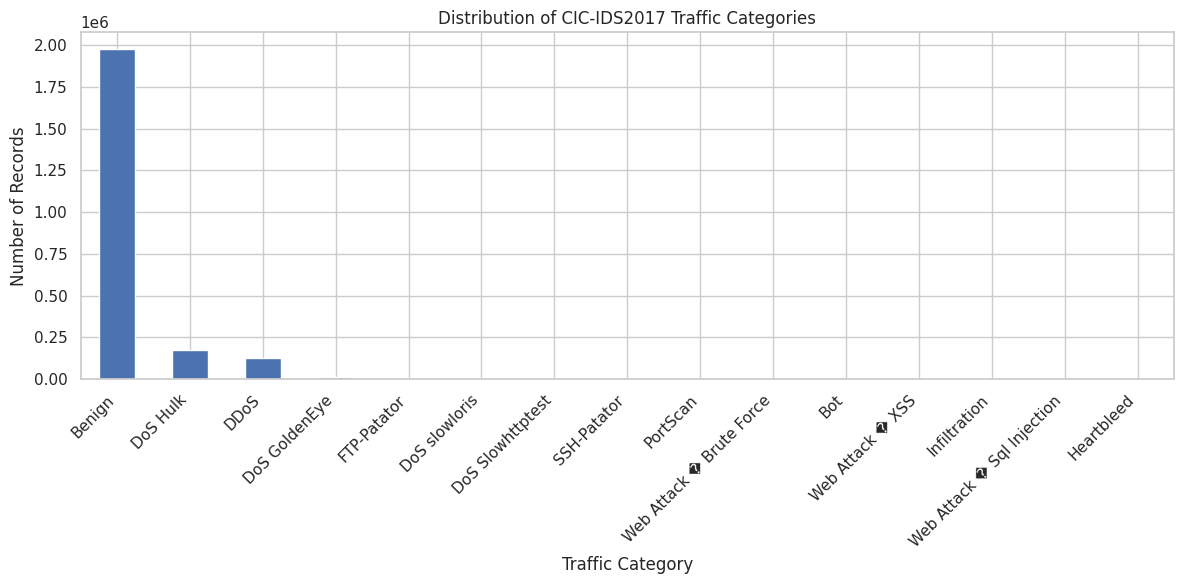

In [14]:
# Create a bar chart showing the number of records per category
plt.figure(figsize=(12, 6))

# Plot the category counts
label_counts.plot(kind="bar")

# Add a title and axis labels
plt.title("Distribution of CIC-IDS2017 Traffic Categories")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")

# Rotate category names for readability
plt.xticks(rotation=45, ha="right")

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

**Checking data quality:**

Before training, we need to check missing values, infinite values, and duplicate rows. Will record these issues first rather than automatically deleting data.

**Check missing values:**

In [15]:
# Count missing values in every column
missing_values = df.isnull().sum()

# Keep only columns that contain missing values
missing_values = missing_values[missing_values > 0]

# Display the result
if missing_values.empty:
    print("No missing values found in the dataset.")
else:
    print("Columns containing missing values:")
    display(missing_values.to_frame(name="Missing Values"))

No missing values found in the dataset.


**Check infinite values:**

In [16]:
# Select only numerical columns
numeric_df = df.select_dtypes(include=[np.number])

# Count positive and negative infinite values in each numerical column
infinite_counts = np.isinf(numeric_df).sum()

# Keep only columns that contain infinite values
infinite_counts = infinite_counts[infinite_counts > 0]

# Display the result
if infinite_counts.empty:
    print("No infinite values found.")
else:
    print("Columns containing infinite values:")
    display(infinite_counts.to_frame(name="Infinite Values"))

No infinite values found.


**Check duplicate records:**

In [17]:
# Count the number of completely duplicated rows
duplicate_count = df.duplicated().sum()

# Display the duplicate count
print("Number of duplicate rows:", duplicate_count)

# Calculate the percentage of duplicate rows
duplicate_percentage = (duplicate_count / len(df)) * 100

# Display the percentage
print("Duplicate percentage:", round(duplicate_percentage, 2), "%")

Number of duplicate rows: 82004
Duplicate percentage: 3.54 %


**Creating classification labels:**

This project has two classification tasks:
1. Binary classification: Identify traffic as Benign or Attack.
2. Multiclass classification: Identify the specific traffic or attack category.

We'll create two target columns while keeping the original Label column for reference.

**Prepare the original labels:**

In [18]:
# Remove rows where the original label is missing
df = df.dropna(subset=[label_column]).copy()

# Remove unnecessary spaces around label names
df[label_column] = df[label_column].astype(str).str.strip()

# Create a separate column for multiclass classification
df["Multiclass_Label"] = df[label_column]

# Display the available multiclass categories
print("Available multiclass categories:")
print(df["Multiclass_Label"].unique())

Available multiclass categories:
['Benign' 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection' 'DoS slowloris' 'DoS Slowhttptest'
 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed' 'Infiltration' 'PortScan'
 'FTP-Patator' 'SSH-Patator' 'DDoS' 'Bot']


**Creating the binary target:**

In [19]:
# Identify records labelled as BENIGN, ignoring letter case
benign_mask = df["Multiclass_Label"].str.upper() == "BENIGN"

# Check that the dataset contains benign records
if not benign_mask.any():
    raise ValueError("BENIGN category was not found. Check the label names.")

# Assign Benign to normal traffic and Attack to all other categories
df["Binary_Label"] = np.where(
    benign_mask,
    "Benign",
    "Attack"
)

# Display the binary classification counts
print("Binary classification distribution:")
display(df["Binary_Label"].value_counts().to_frame(name="Record Count"))

Binary classification distribution:


,Record Count
Binary_Label,
Benign,1977318
Attack,336492


**Visualizing binary classification:**

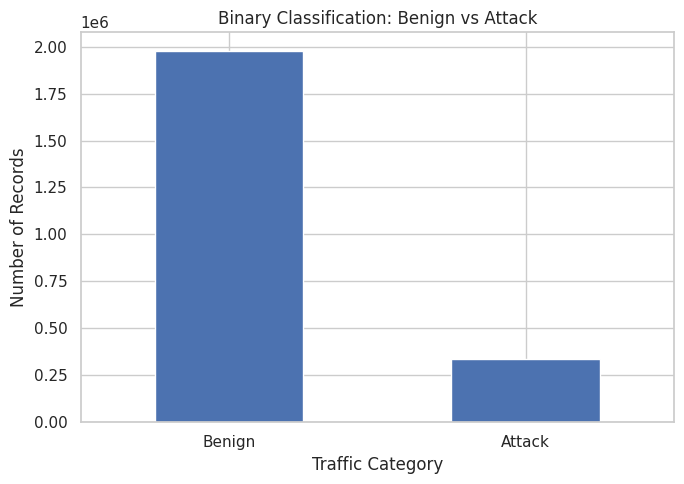

In [20]:
# Count the records in each binary category
binary_counts = df["Binary_Label"].value_counts()

# Create a bar chart
plt.figure(figsize=(7, 5))

# Plot the binary category counts
binary_counts.plot(kind="bar")

# Add chart labels and title
plt.title("Binary Classification: Benign vs Attack")
plt.xlabel("Traffic Category")
plt.ylabel("Number of Records")

# Display the chart
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Verifying both targets:**

A preview of the three label columns, the updated dataset dimensions, and the number of categories for both classification tasks.

In [21]:
# Display the original and newly created target columns
display(df[[label_column, "Multiclass_Label", "Binary_Label"]].head(10))

# Confirm the number of records in the dataset
print("Final dataset shape:", df.shape)

# Confirm the number of multiclass categories
print("Number of multiclass categories:",
      df["Multiclass_Label"].nunique())

# Confirm the number of binary categories
print("Number of binary categories:",
      df["Binary_Label"].nunique())

,Label,Multiclass_Label,Binary_Label
0,Benign,Benign,Benign
1,Benign,Benign,Benign
2,Benign,Benign,Benign
3,Benign,Benign,Benign
4,Benign,Benign,Benign
5,Benign,Benign,Benign
6,Benign,Benign,Benign
7,Benign,Benign,Benign
8,Benign,Benign,Benign
9,Benign,Benign,Benign


Final dataset shape: (2313810, 80)
Number of multiclass categories: 15
Number of binary categories: 2


**Saving the prepared dataset:**

In [22]:
# Save the prepared dataset as a CSV file
df.to_csv(
    "CICIDS2017_Prepared_Data.csv",
    index=False
)

# Confirm that the file was saved
print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


##  Feature Preparation and Data Leakage Prevention

Prepares numerical network traffic features for machine learning.
Target labels and direct identifiers are excluded from the input features to
reduce the risk of data leakage.

**Identifying columns to exclude:**

Will automatically identify direct identifiers and metadata columns. Will also identify non-numerical columns because the first model comparison will use numerical network-flow features.

In [23]:
# List columns that identify a particular network flow or device
identifier_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp"
]

# Keep only identifier columns that actually exist in the dataset
identifier_columns = [
    column for column in identifier_columns
    if column in df.columns
]

# Identify columns that contain non-numerical data
non_numeric_columns = df.select_dtypes(
    exclude=[np.number]
).columns.tolist()

# Display the columns that will be excluded
print("Identifier columns to exclude:")
print(identifier_columns)

print("\nNon-numerical columns:")
print(non_numeric_columns)

Identifier columns to exclude:
[]

Non-numerical columns:
['Label', 'Multiclass_Label', 'Binary_Label']


**Creating the numerical feature dataset:**

Will exclude the original and newly created label columns, identifiers, and non-numerical columns. The remaining columns will be candidate model inputs.

In [24]:
# List all target columns that must not be used as input features
target_columns = [
    label_column,
    "Binary_Label",
    "Multiclass_Label"
]

# Combine target and identifier columns into the exclusion list
excluded_columns = list(set(
    target_columns + identifier_columns
))

# Select numerical columns that are not targets or identifiers
feature_columns = [
    column for column in df.select_dtypes(include=[np.number]).columns
    if column not in excluded_columns
]

# Create the input feature dataset
X = df[feature_columns].copy()

# Display the number of selected features
print("Number of selected features:", X.shape[1])

# Display the selected feature names
print("\nSelected features:")
print(feature_columns)

Number of selected features: 77

Selected features:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Cou

**Handling infinite values and completely empty features:**

Some numerical network-flow features may contain positive infinity, negative infinity, or entirely missing values. Will convert infinity to missing values and remove only columns that have no usable values at all. Other missing values will be handled later using a training-only imputation pipeline.

In [25]:
# Replace positive and negative infinity with missing values
X = X.replace([np.inf, -np.inf], np.nan)

# Identify features that contain only missing values
all_missing_columns = X.columns[X.isna().all()].tolist()

# Remove features that contain no usable values
X = X.drop(columns=all_missing_columns)

# Update the feature column list
feature_columns = X.columns.tolist()

# Display removed columns
print("Completely empty columns removed:")
print(all_missing_columns)

# Display the final feature dimensions
print("\nFeature dataset shape:", X.shape)

# Count remaining missing values
print("Total missing feature values:", X.isna().sum().sum())

Completely empty columns removed:
[]

Feature dataset shape: (2313810, 77)
Total missing feature values: 0


**Verifying the input features:**

This final check confirms that the target columns are not included in the model inputs.

In [26]:
# Check whether any target column appears in the feature list
target_leakage = [
    column for column in target_columns
    if column in X.columns
]

# Display the leakage check
if len(target_leakage) == 0:
    print("Target leakage check passed.")
    print("No target columns are present in the input features.")
else:
    print("WARNING: Target columns found in input features:")
    print(target_leakage)

# Display a preview of the numerical features
display(X.head())

Target leakage check passed.
No target columns are present in the input features.


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,6,113095465,48,24,9668,10012,403,0,201.416672,203.548294,...,23,32,203985.500,5.758372e+05,1629110,379,13800000.0,4277541.0,16500000,6737603
1,6,113473706,68,40,11364,12718,403,0,167.117645,171.919418,...,39,32,178326.875,5.034269e+05,1424245,325,13800000.0,4229413.0,16500000,6945512
2,0,119945515,150,0,0,0,0,0,0.000000,0.000000,...,0,0,6909777.500,1.170000e+07,20400000,6,24400000.0,24300000.0,60100000,5702188
3,6,60261928,9,7,2330,4221,1093,0,258.888885,409.702148,...,8,20,0.000,0.000000e+00,0,0,0.0,0.0,0,0
4,17,269,2,2,102,322,51,51,51.000000,0.000000,...,1,32,0.000,0.000000e+00,0,0,0.0,0.0,0,0


##  Preparing the Modelling Dataset

A reproducible sample of up to 100,000 records is selected for the initial
model comparison. The same input features are used for binary and multiclass
classification.

**Creating a reproducible sample:**

In [27]:
# Import the sampling and splitting function
from sklearn.model_selection import train_test_split

# Set the maximum number of records for the initial experiments
MAX_ROWS = 100000

# Create the multiclass target using the same row indexes as X
y_multiclass = df.loc[X.index, "Multiclass_Label"]

# Count the records in each multiclass category
class_counts = y_multiclass.value_counts()

# Display the smallest class size
print("Smallest multiclass category:", class_counts.min())

# Check that every category has enough records for stratified sampling
if class_counts.min() < 2:
    raise ValueError(
        "At least one category has fewer than two records. "
        "Inspect the category counts before sampling."
    )

# Select a stratified sample if the dataset is larger than MAX_ROWS
if len(X) > MAX_ROWS:

    # Select the sample while preserving category representation
    sample_indices, _ = train_test_split(
        X.index,
        train_size=MAX_ROWS,
        random_state=RANDOM_STATE,
        stratify=y_multiclass
    )

    # Create the sampled feature dataset
    model_X = X.loc[sample_indices].copy()

    # Create the matching multiclass target
    model_y_multiclass = y_multiclass.loc[sample_indices].copy()

else:
    # Use all available records if the dataset is smaller than MAX_ROWS
    model_X = X.copy()
    model_y_multiclass = y_multiclass.copy()

# Create the matching binary target
model_y_binary = df.loc[model_X.index, "Binary_Label"].copy()

# Display the sample dimensions
print("\nModelling dataset prepared.")
print("Number of records:", model_X.shape[0])
print("Number of features:", model_X.shape[1])

Smallest multiclass category: 11

Modelling dataset prepared.
Number of records: 100000
Number of features: 77


**Checking the sampled class distribution:**

Will confirm that the sample includes the different attack categories and both binary classes.

In [28]:
# Display the multiclass category counts in the sample
print("Multiclass sample distribution:")
display(
    model_y_multiclass.value_counts().to_frame(
        name="Record Count"
    )
)

# Display the binary category counts in the sample
print("\nBinary sample distribution:")
display(
    model_y_binary.value_counts().to_frame(
        name="Record Count"
    )
)

Multiclass sample distribution:


,Record Count
Multiclass_Label,
Benign,85457
DoS Hulk,7470
DDoS,5533
DoS GoldenEye,445
FTP-Patator,256
DoS slowloris,233
DoS Slowhttptest,226
SSH-Patator,139
PortScan,85



Binary sample distribution:


,Record Count
Binary_Label,
Benign,85457
Attack,14543


##  Training and Testing Data Split

The dataset is divided into 80% training data and 20% testing data.
Stratified splitting is used to preserve the class distribution.

**Binary classification split:**

In [29]:
# Split the features and binary target into training and testing sets
X_train_binary, X_test_binary, y_train_binary, y_test_binary = train_test_split(
    model_X,
    model_y_binary,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=model_y_binary
)

# Display the training and testing dimensions
print("BINARY CLASSIFICATION")
print("Training features:", X_train_binary.shape)
print("Testing features:", X_test_binary.shape)

# Display the number of records in each set
print("Training records:", len(y_train_binary))
print("Testing records:", len(y_test_binary))

BINARY CLASSIFICATION
Training features: (80000, 77)
Testing features: (20000, 77)
Training records: 80000
Testing records: 20000


In [30]:
# Count records in every multiclass category
multiclass_counts = model_y_multiclass.value_counts()

# Display categories with fewer than two records
rare_classes = multiclass_counts[multiclass_counts < 2]

print("Categories with fewer than 2 records:")
display(rare_classes)

# Display the complete category distribution
print("\nComplete category distribution:")
display(multiclass_counts)

Categories with fewer than 2 records:


,count
Multiclass_Label,
Web Attack � Sql Injection,1



Complete category distribution:


,count
Multiclass_Label,
Benign,85457
DoS Hulk,7470
DDoS,5533
DoS GoldenEye,445
FTP-Patator,256
DoS slowloris,233
DoS Slowhttptest,226
SSH-Patator,139
PortScan,85


In [31]:
# Identify categories containing fewer than five records
rare_classes = multiclass_counts[multiclass_counts < 5]

# Display the categories that will be excluded from this experiment
print("Categories excluded from the initial multiclass experiment:")
display(rare_classes)

# Keep categories with at least five records
valid_classes = multiclass_counts[multiclass_counts >= 5].index

# Create a mask for records belonging to valid categories
valid_mask = model_y_multiclass.isin(valid_classes)

# Create the corrected feature dataset
model_X_multi = model_X.loc[valid_mask].copy()

# Create the corrected multiclass target
model_y_multi = model_y_multiclass.loc[valid_mask].copy()

# Display the corrected dataset size
print("\nCorrected multiclass dataset:")
print("Number of records:", len(model_y_multi))
print("Number of features:", model_X_multi.shape[1])

# Display the updated category counts
display(model_y_multi.value_counts())

Categories excluded from the initial multiclass experiment:


,count
Multiclass_Label,
Infiltration,2
Web Attack � Sql Injection,1



Corrected multiclass dataset:
Number of records: 99997
Number of features: 77


,count
Multiclass_Label,
Benign,85457
DoS Hulk,7470
DDoS,5533
DoS GoldenEye,445
FTP-Patator,256
DoS slowloris,233
DoS Slowhttptest,226
SSH-Patator,139
PortScan,85


**Multiclass classification split:**

In [32]:
# Split the corrected multiclass dataset into training and testing sets
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    model_X_multi,
    model_y_multi,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=model_y_multi
)

# Display the training and testing dimensions
print("MULTICLASS CLASSIFICATION")
print("--------------------------------")

print("Training features:", X_train_multi.shape)
print("Testing features:", X_test_multi.shape)

print("Training records:", len(y_train_multi))
print("Testing records:", len(y_test_multi))

# Display the number of categories
print("\nNumber of training categories:", y_train_multi.nunique())
print("Number of testing categories:", y_test_multi.nunique())

MULTICLASS CLASSIFICATION
--------------------------------
Training features: (79997, 77)
Testing features: (20000, 77)
Training records: 79997
Testing records: 20000

Number of training categories: 12
Number of testing categories: 12


**Verifying the split:**

In [33]:
# Compare the categories in the training and testing sets
print("Categories in training data:")
print(sorted(y_train_multi.unique()))

print("\nCategories in testing data:")
print(sorted(y_test_multi.unique()))

# Check whether all training categories appear in the testing data
if set(y_train_multi.unique()) == set(y_test_multi.unique()):
    print("\nSuccess! All retained categories are represented in both sets.")
else:
    print("\nWarning: Some categories are missing from one of the sets.")

Categories in training data:
['Benign', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � XSS']

Categories in testing data:
['Benign', 'Bot', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'PortScan', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � XSS']

Success! All retained categories are represented in both sets.


**Verifying class representation:**

This check compares the class proportions in the training and testing data.

In [34]:
# Calculate the binary class proportions in the training set
print("Binary training proportions:")
display(y_train_binary.value_counts(normalize=True).round(3))

# Calculate the binary class proportions in the testing set
print("\nBinary testing proportions:")
display(y_test_binary.value_counts(normalize=True).round(3))

# Calculate the multiclass proportions in the training set
print("\nMulticlass training proportions:")
display(y_train_multi.value_counts(normalize=True).round(3))

# Calculate the multiclass proportions in the testing set
print("\nMulticlass testing proportions:")
display(y_test_multi.value_counts(normalize=True).round(3))

Binary training proportions:


,proportion
Binary_Label,
Benign,0.855
Attack,0.145



Binary testing proportions:


,proportion
Binary_Label,
Benign,0.855
Attack,0.145



Multiclass training proportions:


,proportion
Multiclass_Label,
Benign,0.855
DoS Hulk,0.075
DDoS,0.055
DoS GoldenEye,0.004
FTP-Patator,0.003
DoS slowloris,0.002
DoS Slowhttptest,0.002
SSH-Patator,0.001
PortScan,0.001



Multiclass testing proportions:


,proportion
Multiclass_Label,
Benign,0.855
DoS Hulk,0.075
DDoS,0.055
DoS GoldenEye,0.004
FTP-Patator,0.003
DoS slowloris,0.002
DoS Slowhttptest,0.002
SSH-Patator,0.001
PortScan,0.001


## Data Preprocessing

Missing numerical values are replaced using the median, and numerical
features are standardised. Preprocessing is included inside machine
learning pipelines so that it is fitted only on training data.

**Importing preprocessing tools:**

In [35]:
# Import the median imputer
from sklearn.impute import SimpleImputer

# Import the feature standardisation tool
from sklearn.preprocessing import StandardScaler

# Import Pipeline to combine preprocessing and machine learning
from sklearn.pipeline import Pipeline

# Import the Logistic Regression algorithm
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Confirm successful imports
print("Preprocessing and evaluation tools imported successfully!")

Preprocessing and evaluation tools imported successfully!


**Creating the preprocessing pipeline:**

In [36]:
# Create a pipeline for numerical feature preprocessing
preprocessor = Pipeline([

    # Replace missing values with the median of each feature
    ("imputer", SimpleImputer(strategy="median")),

    # Standardise features to a common numerical scale
    ("scaler", StandardScaler())
])

# Confirm the preprocessing pipeline
print("Preprocessing pipeline created successfully!")
print(preprocessor)

Preprocessing pipeline created successfully!
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


**Training first binary classification model:**

**Creating the Logistic Regression pipeline:**



In [37]:
# Create a complete machine learning pipeline
logistic_model = Pipeline([

    # Fill missing values using training-set medians
    ("imputer", SimpleImputer(strategy="median")),

    # Standardise the numerical features
    ("scaler", StandardScaler()),

    # Train Logistic Regression with balanced class weights
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Confirm that the model has been created
print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


**Training the model:**

trains Logistic Regression using only the binary training data. Training time is also recorded for later comparison.

In [38]:
# Record the starting time
start_time = time.time()

# Train the model using the training features and labels
logistic_model.fit(X_train_binary, y_train_binary)

# Calculate the total training time
logistic_training_time = time.time() - start_time

# Display the training time
print("Logistic Regression training completed!")
print("Training time:", round(logistic_training_time, 2), "seconds")

Logistic Regression training completed!
Training time: 10.22 seconds


**Making predictions:**

The trained model will predict the labels for the testing data, which it has not seen during training.

In [39]:
# Predict the binary labels for the testing data
y_pred_logistic = logistic_model.predict(X_test_binary)

# Display the first 10 actual labels
print("Actual labels:")
print(y_test_binary.head(10).tolist())

# Display the first 10 predicted labels
print("\nPredicted labels:")
print(y_pred_logistic[:10].tolist())

Actual labels:
['Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Benign', 'Benign']

Predicted labels:
['Benign', 'Benign', 'Benign', 'Benign', 'Benign', 'Attack', 'Benign', 'Benign', 'Benign', 'Benign']


**Evaluating Logistic Regression:**

Will calculate accuracy, precision, recall, and macro F1-score. These metrics help us understand how well the model identifies both traffic categories.

In [40]:
# Calculate the accuracy of the model
logistic_accuracy = accuracy_score(
    y_test_binary,
    y_pred_logistic
)

# Calculate macro precision
logistic_precision = precision_score(
    y_test_binary,
    y_pred_logistic,
    average="macro",
    zero_division=0
)

# Calculate macro recall
logistic_recall = recall_score(
    y_test_binary,
    y_pred_logistic,
    average="macro",
    zero_division=0
)

# Calculate macro F1-score
logistic_f1 = f1_score(
    y_test_binary,
    y_pred_logistic,
    average="macro",
    zero_division=0
)

# Display the evaluation results
print("LOGISTIC REGRESSION - BINARY CLASSIFICATION")
print("--------------------------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Macro Precision:", round(logistic_precision, 4))
print("Macro Recall:", round(logistic_recall, 4))
print("Macro F1-score:", round(logistic_f1, 4))
print("Training Time:", round(logistic_training_time, 2), "seconds")

LOGISTIC REGRESSION - BINARY CLASSIFICATION
--------------------------------------------
Accuracy: 0.9344
Macro Precision: 0.8464
Macro Recall: 0.9448
Macro F1-score: 0.885
Training Time: 10.22 seconds


**Classification report:**

A report showing precision, recall, F1-score, and support for each class, along with macro and weighted averages.

In [41]:
# Generate a detailed classification report
print(
    classification_report(
        y_test_binary,
        y_pred_logistic,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Attack       0.70      0.96      0.81      2909
      Benign       0.99      0.93      0.96     17091

    accuracy                           0.93     20000
   macro avg       0.85      0.94      0.88     20000
weighted avg       0.95      0.93      0.94     20000



**Confusion matrix:**

The confusion matrix shows how many records were classified correctly and incorrectly.

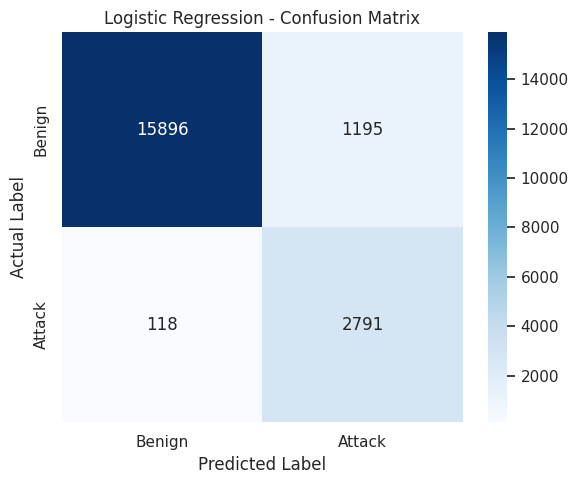

In [42]:
# Define the order of the binary classes
binary_class_names = ["Benign", "Attack"]

# Calculate the confusion matrix
logistic_cm = confusion_matrix(
    y_test_binary,
    y_pred_logistic,
    labels=binary_class_names
)

# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=binary_class_names,
    yticklabels=binary_class_names
)

# Add chart labels
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Display the chart
plt.tight_layout()
plt.show()

**Calculating False Positive Rate (FPR):**

FPR measures how often normal traffic is incorrectly identified as an attack. This is especially important for intrusion detection systems because too many false alarms can make the system less useful.

In [43]:
# Extract TN, FP, FN, and TP from the confusion matrix
tn, fp, fn, tp = logistic_cm.ravel()

# Calculate False Positive Rate
if (fp + tn) > 0:
    logistic_fpr = fp / (fp + tn)
else:
    logistic_fpr = 0

# Display the confusion matrix values
print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

# Display the False Positive Rate
print("\nFalse Positive Rate:", round(logistic_fpr, 4))

True Negative: 15896
False Positive: 1195
False Negative: 118
True Positive: 2791

False Positive Rate: 0.0699


## Binary Classification – Model Comparison

Four additional machine learning algorithms are trained and evaluated:
Decision Tree, Random Forest, XGBoost, and Linear SVM.

All models use the same training and testing data to ensure a fair comparison.

**Importing the additional algorithms:**

Importing the four algorithms and the tools needed to compare their performance.

In [44]:
# Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Import Linear SVM
from sklearn.svm import LinearSVC

# Import XGBoost
from xgboost import XGBClassifier

# Import pandas for storing model results
import pandas as pd

# Confirm successful imports
print("All additional machine learning algorithms imported!")

All additional machine learning algorithms imported!


**Creating the four model pipelines:**

Each model gets its own preprocessing pipeline. The median imputer and scaler are fitted using the training data only.

In [45]:
# Create the Decision Tree pipeline
decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Create the Random Forest pipeline
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Create the Linear SVM pipeline
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
        dual="auto"
    ))
])

# Confirm that the three pipelines were created
print("Decision Tree, Random Forest, and Linear SVM pipelines created!")

Decision Tree, Random Forest, and Linear SVM pipelines created!


**Preparing XGBoost:**

XGBoost requires numerical class labels. We'll encode Benign and Attack as numbers for training, then convert its predictions back to their original names.

In [46]:
# Import LabelEncoder for converting text labels into numbers
from sklearn.preprocessing import LabelEncoder

# Import a tool for calculating balanced sample weights
from sklearn.utils.class_weight import compute_sample_weight

# Create the label encoder
binary_encoder = LabelEncoder()

# Convert the training labels into numerical values
y_train_xgb = binary_encoder.fit_transform(y_train_binary)

# Create the XGBoost pipeline
xgboost_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Calculate balanced weights for the training records
xgb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_xgb
)

# Display the numerical label mapping
print("XGBoost label mapping:")
for number, category in enumerate(binary_encoder.classes_):
    print(number, "=", category)

print("\nXGBoost pipeline created successfully!")

XGBoost label mapping:
0 = Attack
1 = Benign

XGBoost pipeline created successfully!


**Training the four models:**

This cell trains Decision Tree, Random Forest, XGBoost, and Linear SVM. It records the training time for each model.

In [47]:
# Store the four models in a dictionary
additional_models = {
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": xgboost_model,
    "Linear SVM": svm_model
}

# Create a dictionary to store predictions
additional_predictions = {}

# Create a dictionary to store training times
additional_training_times = {}

# Train each model one at a time
for model_name, model in additional_models.items():

    # Display the current model name
    print("\nTraining:", model_name)

    # Record the starting time
    start_time = time.time()

    # Train XGBoost using encoded labels and balanced sample weights
    if model_name == "XGBoost":
        model.fit(
            X_train_binary,
            y_train_xgb,
            classifier__sample_weight=xgb_sample_weights
        )

        # Predict numerical labels
        encoded_predictions = model.predict(X_test_binary)

        # Convert predictions back to original category names
        predictions = binary_encoder.inverse_transform(
            encoded_predictions.astype(int)
        )

    else:
        # Train the other models using the original text labels
        model.fit(X_train_binary, y_train_binary)

        # Generate predictions for the testing data
        predictions = model.predict(X_test_binary)

    # Calculate the training time
    training_time = time.time() - start_time

    # Store the predictions and training time
    additional_predictions[model_name] = predictions
    additional_training_times[model_name] = training_time

    # Display the result
    print("Training completed!")
    print("Training time:", round(training_time, 2), "seconds")


Training: Decision Tree
Training completed!
Training time: 10.43 seconds

Training: Random Forest
Training completed!
Training time: 30.33 seconds

Training: XGBoost
Training completed!
Training time: 14.39 seconds

Training: Linear SVM
Training completed!
Training time: 15.56 seconds


**Evaluating all five binary models:**

Will calculate the same metrics for Logistic Regression and the four additional models. This makes the comparison consistent.

In [48]:
# Create a dictionary containing predictions from all five models
all_binary_predictions = {
    "Logistic Regression": y_pred_logistic,
    **additional_predictions
}

# Store the training times of all five models
all_binary_times = {
    "Logistic Regression": logistic_training_time,
    **additional_training_times
}

# Create an empty list to store evaluation results
binary_results = []

# Evaluate each model
for model_name, predictions in all_binary_predictions.items():

    # Calculate the confusion matrix in a fixed class order
    cm = confusion_matrix(
        y_test_binary,
        predictions,
        labels=["Benign", "Attack"]
    )

    # Extract true negatives, false positives, false negatives and true positives
    tn, fp, fn, tp = cm.ravel()

    # Calculate False Positive Rate
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    # Store the model's evaluation metrics
    binary_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_binary, predictions),
        "Precision": precision_score(
            y_test_binary, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test_binary, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test_binary, predictions,
            average="macro", zero_division=0
        ),
        "FPR": fpr,
        "Training Time (seconds)": all_binary_times[model_name]
    })

# Convert the results into a DataFrame
binary_results_df = pd.DataFrame(binary_results)

# Sort the results by Macro F1-score
binary_results_df = binary_results_df.sort_values(
    by="Macro F1",
    ascending=False
)

# Display the final comparison table
display(binary_results_df.round(4))

,Model,Accuracy,Precision,Recall,Macro F1,FPR,Training Time (seconds)
3,XGBoost,0.9985,0.9964,0.9976,0.9970,0.0011,14.3878
1,Decision Tree,0.9978,0.9961,0.9948,0.9955,0.0011,10.4303
2,Random Forest,0.9975,0.9968,0.9931,0.9950,0.0007,30.3327
0,Logistic Regression,0.9344,0.8464,0.9448,0.8850,0.0699,10.2206
4,Linear SVM,0.9304,0.8393,0.9465,0.8800,0.0761,15.5627


**Visualizing model performance:**

A bar chart will help compare the Macro F1-scores of the five models.

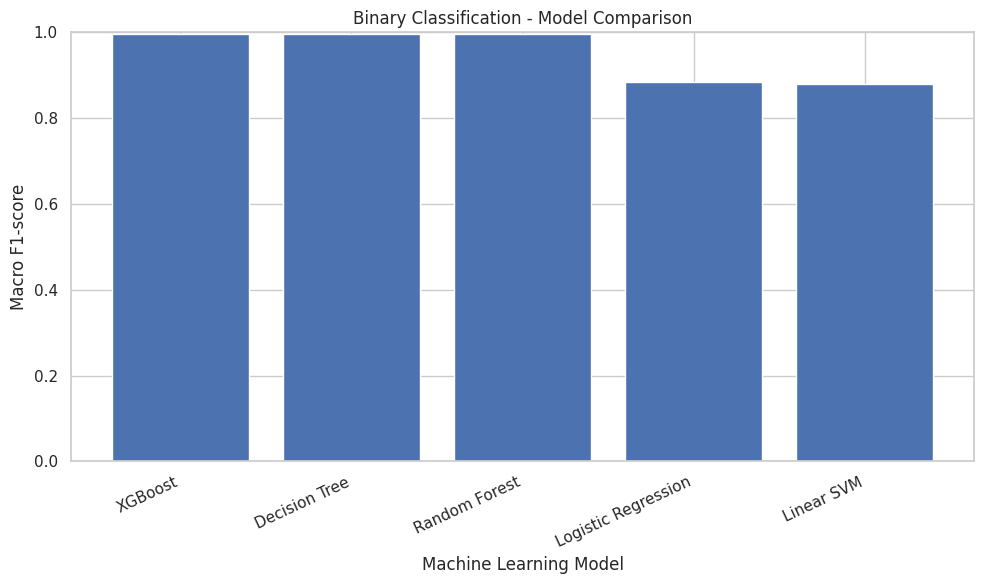

In [49]:
# Create a figure for the comparison chart
plt.figure(figsize=(10, 6))

# Plot the Macro F1-score for each model
plt.bar(
    binary_results_df["Model"],
    binary_results_df["Macro F1"]
)

# Add chart title and labels
plt.title("Binary Classification - Model Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Macro F1-score")

# Set the vertical axis range
plt.ylim(0, 1)

# Rotate model names for readability
plt.xticks(rotation=25, ha="right")

# Display the chart
plt.tight_layout()
plt.show()

**Identifing the best binary model:**

identifies the model with the highest Macro F1-score. Will use it for further inspection.

In [50]:
# Find the row with the highest Macro F1-score
best_binary_result = binary_results_df.iloc[0]

# Extract the name of the best model
best_binary_model_name = best_binary_result["Model"]

# Display the best model
print("Best binary classification model:")
print(best_binary_model_name)

# Display its evaluation metrics
display(best_binary_result.to_frame(name="Value"))

Best binary classification model:
XGBoost


,Value
Model,XGBoost
Accuracy,0.9985
Precision,0.996421
Recall,0.997553
Macro F1,0.996986
FPR,0.001112
Training Time (seconds),14.387822


**Save binary model comparison results:**

In [51]:
# Save the binary model comparison table
binary_results_df.to_csv(
    "Binary_Classification_Results.csv",
    index=False
)

# Confirm that the file was saved
print("Binary classification results saved successfully!")

Binary classification results saved successfully!


**Inspecting the best model's confusion matrix:**

Will display the confusion matrix for the best-performing model, based on Macro F1-score.

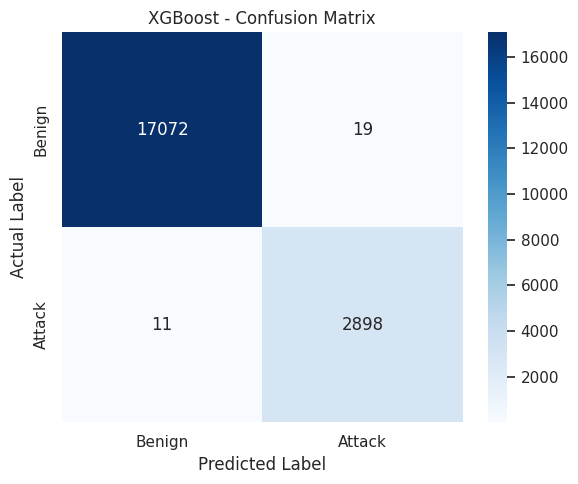

In [52]:
# Retrieve predictions from the best binary model
best_binary_predictions = all_binary_predictions[
    best_binary_model_name
]

# Calculate its confusion matrix
best_binary_cm = confusion_matrix(
    y_test_binary,
    best_binary_predictions,
    labels=["Benign", "Attack"]
)

# Display the confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    best_binary_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Attack"],
    yticklabels=["Benign", "Attack"]
)

# Add chart labels
plt.title(f"{best_binary_model_name} - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

# Display the chart
plt.tight_layout()
plt.show()

## Multiclass Classification

This section trains machine learning models to identify different
network traffic categories in the CIC-IDS2017 dataset.

The models are evaluated using accuracy, macro precision, macro recall,
macro F1-score, and training time.

**Checking the multiclass training data:**

Confirms that the corrected training and testing datasets exist and contain the same categories.

In [53]:
# Display the dimensions of the multiclass training dataset
print("Training feature shape:", X_train_multi.shape)

# Display the dimensions of the multiclass testing dataset
print("Testing feature shape:", X_test_multi.shape)

# Display the number of training categories
print("\nTraining categories:", y_train_multi.nunique())

# Display the number of testing categories
print("Testing categories:", y_test_multi.nunique())

# Check that both datasets contain the same categories
if set(y_train_multi.unique()) == set(y_test_multi.unique()):
    print("\nAll retained categories are present in both datasets.")
else:
    print("\nWarning: The training and testing categories do not match.")

Training feature shape: (79997, 77)
Testing feature shape: (20000, 77)

Training categories: 12
Testing categories: 12

All retained categories are present in both datasets.


**Creating the multiclass models:**

Will compare the same five algorithms used in binary classification.

**Creating the model pipelines:**

Each algorithm gets its own preprocessing pipeline. We use balanced class weights for Decision Tree, Random Forest, Logistic Regression, and Linear SVM to help address class imbalance.

In [54]:
# Create a multiclass Logistic Regression pipeline
multi_logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Create a multiclass Decision Tree pipeline
multi_decision_tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

# Create a multiclass Random Forest pipeline
multi_random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

# Create a multiclass Linear SVM pipeline
multi_svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=RANDOM_STATE,
        dual="auto"
    ))
])

# Display confirmation
print("Four multiclass model pipelines created successfully!")

Four multiclass model pipelines created successfully!


**Preparing multiclass labels for XGBoost:**

XGBoost needs the text attack categories converted into numerical values. Will use LabelEncoder and retain the mapping for interpreting the predictions later.

In [55]:
# Create a label encoder for multiclass categories
multi_encoder = LabelEncoder()

# Encode the training labels
y_train_multi_encoded = multi_encoder.fit_transform(y_train_multi)

# Encode the testing labels using the same mapping
y_test_multi_encoded = multi_encoder.transform(y_test_multi)

# Count the number of retained categories
number_of_classes = len(multi_encoder.classes_)

# Display the category-to-number mapping
print("Multiclass label mapping:")

for number, category in enumerate(multi_encoder.classes_):
    print(number, "=", category)

# Display the number of categories
print("\nNumber of classes:", number_of_classes)

Multiclass label mapping:
0 = Benign
1 = Bot
2 = DDoS
3 = DoS GoldenEye
4 = DoS Hulk
5 = DoS Slowhttptest
6 = DoS slowloris
7 = FTP-Patator
8 = PortScan
9 = SSH-Patator
10 = Web Attack � Brute Force
11 = Web Attack � XSS

Number of classes: 12
